# Bulldozer Price Prediction: Finding a Better Regression Model

The original notebook (`end-end-bulldozer-price-regression.ipynb`) used a **Random Forest** and reached a validation RMSLE of **0.245** on 2012 sales.

This notebook asks: **which regression model works best on this dataset, and how much better is it?**

We compare five models on exactly the same data, features and validation set:

| Model | Family |
|---|---|
| Random Forest | bagging (the original approach) |
| HistGradientBoosting (scikit-learn) | gradient boosting |
| XGBoost | gradient boosting |
| LightGBM | gradient boosting with native categorical support |
| CatBoost | gradient boosting with ordered target encoding of categories |

**Fair-comparison rules**

1. **Same split as the original:** train on sales before 2012, report the final score on 2012 sales (11,573 rows).
2. **No tuning on 2012:** the number of boosting rounds is chosen by training on sales before 2011 and checking 2011 (early stopping). The final model is refit on all pre-2012 data. 2012 is used **once**, for the final score.
3. **Same features for every model**, with the category encoding learned from the training data only (fixing the original notebook's test-set encoding problem).
4. **Log target:** every model is trained on `log1p(SalePrice)`, so minimising squared error directly minimises RMSLE. Predictions are converted back with `expm1`.

In [1]:
import time, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import root_mean_squared_log_error, mean_absolute_error, r2_score, mean_absolute_percentage_error
import lightgbm as lgb
import xgboost as xgb
import catboost as cb
warnings.filterwarnings("ignore")
print("lightgbm", lgb.__version__, "| xgboost", xgb.__version__, "| catboost", cb.__version__)
RESULTS = {}   # everything the slide deck needs is collected here and saved at the end

lightgbm 4.7.0 | xgboost 3.4.1 | catboost 1.2.10


## 1. Load the data

Same file as the original notebook: `TrainAndValid.csv`, 412,698 sales from 1989 to April 2012, sorted by sale date.

In [2]:
raw = pd.read_csv("../data/raw/bluebook-for-bulldozers/TrainAndValid.csv", low_memory=False, parse_dates=["saledate"])
raw = raw.sort_values("saledate").reset_index(drop=True)
test_raw = pd.read_csv("../data/raw/bluebook-for-bulldozers/Test.csv", low_memory=False, parse_dates=["saledate"])
print(raw.shape, test_raw.shape)

(412698, 53) (12457, 52)


## 2. Feature engineering

Same date features as the original (`saleYear`, `saleMonth`, `saleDay`, `saleDayOfWeek`, `saleDayOfYear`), plus three data-cleaning improvements:

| Change | Why |
|---|---|
| `YearMade = 1000` → missing | 1000 is a placeholder for "unknown", not a real year (about 9.5% of rows) |
| `MachineHoursCurrentMeter = 0` → missing | the data dictionary says 0 means "no hours reported" |
| new `machineAge = saleYear − YearMade` | age at sale is what drives price, and it's easier for trees to use directly |

Missing numeric values are left as `NaN`: all five models handle missing values natively, so median filling and `_is_missing` flags are no longer needed.

In [3]:
def add_features(df):
    df = df.copy()
    df["saleYear"] = df.saledate.dt.year
    df["saleMonth"] = df.saledate.dt.month
    df["saleDay"] = df.saledate.dt.day
    df["saleDayOfWeek"] = df.saledate.dt.dayofweek
    df["saleDayOfYear"] = df.saledate.dt.dayofyear
    df["YearMade"] = df["YearMade"].where(df["YearMade"] > 1900)                      # 1000 = unknown
    df["MachineHoursCurrentMeter"] = df["MachineHoursCurrentMeter"].replace(0, np.nan)  # 0 = not reported
    df["machineAge"] = df["saleYear"] - df["YearMade"]
    return df.drop(columns=["saledate"])

full = add_features(raw)
test_full = add_features(test_raw)
CAT_COLS = [c for c in full.columns if not pd.api.types.is_numeric_dtype(full[c])]
print(len(CAT_COLS), "text columns;", full.shape[1] - 1, "features in total")

44 text columns; 57 features in total


## 3. Train / validation split and consistent category encoding

* **Final split** (same as the original notebook): train = before 2012, validation = 2012.
* **Tuning split:** train = before 2011, early-stopping check = 2011.

Category lists are learned from the **training rows only** and reused for validation and test, so a given model name or state always gets the same code. Values never seen in training become missing.

In [4]:
def encode(train_df, *others):
    """Return copies with text columns as pandas categories using the training categories."""
    cats = {c: pd.Categorical(train_df[c].dropna().unique()).categories for c in CAT_COLS}
    out = []
    for df in (train_df,) + others:
        df = df.copy()
        for c in CAT_COLS:
            df[c] = pd.Categorical(df[c], categories=cats[c])
        out.append(df)
    return out

def to_codes(df):
    """Integer codes for models without native categorical support (missing/unseen = -1 -> NaN)."""
    df = df.copy()
    for c in CAT_COLS:
        df[c] = df[c].cat.codes.replace(-1, np.nan).astype("float32")
    return df

def split(df, year):
    tr, va = df[df.saleYear < year], df[df.saleYear == year]
    # training target on the log scale; validation target kept in dollars (log it when a model needs it)
    return tr.drop(columns="SalePrice"), np.log1p(tr.SalePrice), va.drop(columns="SalePrice"), va.SalePrice

# Final split (validate on 2012) and tuning split (early-stop on 2011)
X_tr, y_tr, X_va, y_va = split(full, 2012)
X_tr, X_va, X_te = encode(X_tr, X_va, test_full)
Xa_tr, ya_tr, Xa_va, ya_va = split(full[full.saleYear < 2012], 2011)
Xa_tr, Xa_va = encode(Xa_tr, Xa_va)
print("final:", X_tr.shape, X_va.shape, "| tuning:", Xa_tr.shape, Xa_va.shape, "| test:", X_te.shape)

final: (401125, 57) (11573, 57) | tuning: (365928, 57) (35197, 57) | test: (12457, 57)


## 4. Evaluation

Same metrics as the original notebook, plus **MAPE** (average percentage error), which is the easiest to explain to a business audience.

In [5]:
def scores(y_true, pred):
    return {"RMSLE": root_mean_squared_log_error(y_true, pred), "MAE": mean_absolute_error(y_true, pred),
            "R2": r2_score(y_true, pred), "MAPE": mean_absolute_percentage_error(y_true, pred)}

def evaluate(name, model, Xtr, Xva, fit_seconds, rounds=None):
    p_va = np.expm1(model.predict(Xva))
    p_tr = np.expm1(model.predict(Xtr))
    s = scores(y_va, p_va)
    s["Train RMSLE"] = root_mean_squared_log_error(np.expm1(y_tr), p_tr)
    s["Fit seconds"] = fit_seconds
    s["Rounds"] = rounds
    RESULTS.setdefault("models", {})[name] = s
    print(f"{name:<22} valid RMSLE {s['RMSLE']:.4f} | MAE ${s['MAE']:,.0f} | R2 {s['R2']:.3f} | "
          f"MAPE {s['MAPE']*100:.1f}% | train RMSLE {s['Train RMSLE']:.4f} | {fit_seconds:.0f}s")
    return p_va
PREDS = {}

## 5. The models

### 5.1 Random Forest (the original model's settings)

Same hyperparameters as the original `ideal_model`, but trained on the log target and the cleaned features, so we can see how much of any gain comes from the model rather than the data preparation.

In [6]:
Xc_tr, Xc_va, Xc_te = to_codes(X_tr), to_codes(X_va), to_codes(X_te)
t = time.time()
rf = RandomForestRegressor(n_estimators=40, min_samples_leaf=1, min_samples_split=14, max_features=0.5,
                           n_jobs=-1, random_state=42).fit(Xc_tr, y_tr)
PREDS["Random Forest"] = evaluate("Random Forest", rf, Xc_tr, Xc_va, time.time() - t, 40)

Random Forest          valid RMSLE 0.2500 | MAE $6,435 | R2 0.852 | MAPE 18.6% | train RMSLE 0.1345 | 14s


### 5.2 HistGradientBoosting (scikit-learn)

scikit-learn's fast gradient boosting. The best number of iterations is found on the 2011 check set with `staged_predict`, then the model is refit on all pre-2012 data.

In [7]:
hgb_params = dict(learning_rate=0.1, max_leaf_nodes=127, min_samples_leaf=20, l2_regularization=1.0, random_state=42)
h = HistGradientBoostingRegressor(max_iter=1500, early_stopping=False, **hgb_params).fit(to_codes(Xa_tr), ya_tr)
curve = [root_mean_squared_log_error(ya_va, np.expm1(p).clip(0)) for p in h.staged_predict(to_codes(Xa_va))]
best_hgb = int(np.argmin(curve)) + 1
t = time.time()
hgb = HistGradientBoostingRegressor(max_iter=int(best_hgb * 1.1), early_stopping=False, **hgb_params).fit(Xc_tr, y_tr)
PREDS["HistGradientBoosting"] = evaluate("HistGradientBoosting", hgb, Xc_tr, Xc_va, time.time() - t, int(best_hgb * 1.1))

HistGradientBoosting   valid RMSLE 0.2460 | MAE $6,358 | R2 0.857 | MAPE 18.5% | train RMSLE 0.1710 | 40s


### 5.3 XGBoost

Histogram-based XGBoost with row and column subsampling. Early stopping on 2011 picks the number of trees.

In [8]:
xgb_params = dict(learning_rate=0.05, max_depth=10, min_child_weight=5, subsample=0.8, colsample_bytree=0.7,
                  reg_lambda=1.0, tree_method="hist", n_jobs=-1, random_state=42)
x = xgb.XGBRegressor(n_estimators=5000, early_stopping_rounds=100, **xgb_params)
x.fit(to_codes(Xa_tr), ya_tr, eval_set=[(to_codes(Xa_va), np.log1p(ya_va))], verbose=False)
best_xgb = x.best_iteration + 1
t = time.time()
xgbm = xgb.XGBRegressor(n_estimators=int(best_xgb * 1.1), **xgb_params).fit(Xc_tr, y_tr)
PREDS["XGBoost"] = evaluate("XGBoost", xgbm, Xc_tr, Xc_va, time.time() - t, int(best_xgb * 1.1))

XGBoost                valid RMSLE 0.2380 | MAE $6,100 | R2 0.867 | MAPE 17.9% | train RMSLE 0.1593 | 30s


### 5.4 LightGBM

LightGBM grows trees leaf-wise and splits **categorical columns natively**: instead of treating a model code as a number, it groups categories by their effect on price. This suits high-cardinality columns such as `fiModelDesc`.

In [9]:
lgb_params = dict(learning_rate=0.05, num_leaves=255, min_child_samples=20, subsample=0.8, subsample_freq=1,
                  colsample_bytree=0.7, reg_lambda=1.0, cat_smooth=10, max_cat_to_onehot=8,
                  n_jobs=-1, random_state=42, verbose=-1)
l = lgb.LGBMRegressor(n_estimators=10000, **lgb_params)
l.fit(Xa_tr, ya_tr, eval_set=[(Xa_va, np.log1p(ya_va))], callbacks=[lgb.early_stopping(150, verbose=False)])
best_lgb = l.best_iteration_
t = time.time()
lgbm = lgb.LGBMRegressor(n_estimators=int(best_lgb * 1.1), **lgb_params).fit(X_tr, y_tr)
PREDS["LightGBM"] = evaluate("LightGBM", lgbm, X_tr, X_va, time.time() - t, int(best_lgb * 1.1))

LightGBM               valid RMSLE 0.2334 | MAE $6,027 | R2 0.869 | MAPE 17.5% | train RMSLE 0.1739 | 33s


### 5.5 CatBoost

CatBoost encodes categories with **ordered target statistics**, designed to avoid target leakage, and builds symmetric trees. It needs text categories with no missing values, so missing is marked as `"missing"`.

In [10]:
def cb_frame(df):
    df = df.copy()
    for c in CAT_COLS:
        df[c] = df[c].astype(object).fillna("missing").astype(str)
    return df
cb_params = dict(learning_rate=0.08, depth=8, l2_leaf_reg=3, loss_function="RMSE", thread_count=-1,
                 random_seed=42, verbose=0, one_hot_max_size=8)
c = cb.CatBoostRegressor(iterations=4000, od_type="Iter", od_wait=150, **cb_params)
c.fit(cb_frame(Xa_tr), ya_tr, cat_features=CAT_COLS, eval_set=(cb_frame(Xa_va), np.log1p(ya_va)), use_best_model=True)
best_cb = c.get_best_iteration() + 1
t = time.time()
cbm = cb.CatBoostRegressor(iterations=int(best_cb * 1.1), **cb_params).fit(cb_frame(X_tr), y_tr, cat_features=CAT_COLS)
PREDS["CatBoost"] = evaluate("CatBoost", cbm, cb_frame(X_tr), cb_frame(X_va), time.time() - t, int(best_cb * 1.1))

CatBoost               valid RMSLE 0.2309 | MAE $5,977 | R2 0.873 | MAPE 17.4% | train RMSLE 0.1945 | 1017s


## 6. Model comparison

The original notebook's Random Forest (raw target, original preprocessing) scored **0.2452** on the same 2012 validation set. Lower RMSLE is better.

In [11]:
RESULTS["original_rf"] = {"RMSLE": 0.24524, "MAE": 5951.25, "R2": 0.8818, "Train RMSLE": 0.14469}
table = pd.DataFrame(RESULTS["models"]).T.sort_values("RMSLE")
table.loc["Original notebook RF"] = [0.24524, 5951.25, 0.8818, np.nan, 0.14469, np.nan, 40]
table.style.format({"RMSLE": "{:.4f}", "MAE": "${:,.0f}", "R2": "{:.3f}", "MAPE": "{:.1%}", "Train RMSLE": "{:.4f}", "Fit seconds": "{:.0f}"})

,RMSLE,MAE,R2,MAPE,Train RMSLE,Fit seconds,Rounds
CatBoost,0.2309,"$5,977",0.873,17.4%,0.1945,1017,1364.000000
LightGBM,0.2334,"$6,027",0.869,17.5%,0.1739,33,212.000000
XGBoost,0.2380,"$6,100",0.867,17.9%,0.1593,30,643.000000
HistGradientBoosting,0.2460,"$6,358",0.857,18.5%,0.1710,40,695.000000
Random Forest,0.2500,"$6,435",0.852,18.6%,0.1345,14,40.000000
Original notebook RF,0.2452,"$5,951",0.882,nan%,0.1447,nan,40.000000


Best model: CatBoost


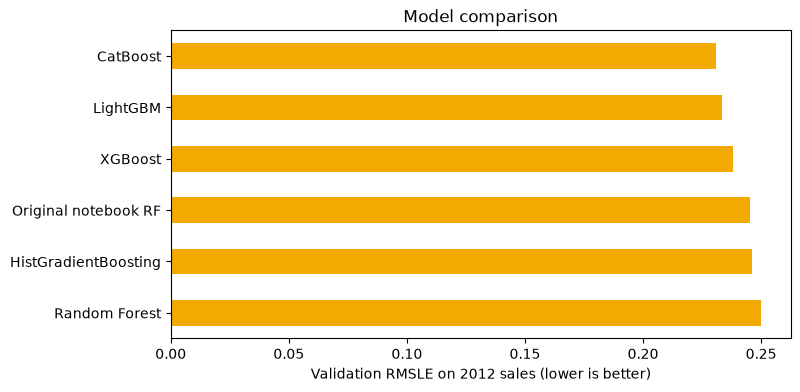

In [12]:
BEST = table.drop("Original notebook RF")["RMSLE"].idxmin()
RESULTS["best"] = BEST
print("Best model:", BEST)
ax = table["RMSLE"].sort_values(ascending=False).plot.barh(figsize=(8, 4), color="#F2A900")
ax.set_xlabel("Validation RMSLE on 2012 sales (lower is better)"); ax.set_title("Model comparison"); plt.show()

### Does averaging the best models help?

Different model families make different mistakes, so a simple average of the best boosting models can beat each one alone.

In [13]:
top = table.drop("Original notebook RF").sort_values("RMSLE").index[:3].tolist()
blend = np.expm1(np.mean([np.log1p(PREDS[m]) for m in top], axis=0))
s = scores(y_va, blend)
RESULTS["blend"] = {"models": top, **s}
print("Blend of", top, f"-> RMSLE {s['RMSLE']:.4f}, MAE ${s['MAE']:,.0f}, R2 {s['R2']:.3f}")

Blend of ['CatBoost', 'LightGBM', 'XGBoost'] -> RMSLE 0.2275, MAE $5,908, R2 0.875


## 7. Deeper evaluation

The diagnostics below (log-target check, time-based cross-validation, learning curve and SHAP importance) use **LightGBM**, because it refits in about 30 seconds while CatBoost takes over 15 minutes, and its accuracy is almost the same. The error breakdown in 7.5 uses the best model's own predictions.

### 7.1 Does the log target matter?

Same LightGBM settings, trained on raw prices instead of `log1p(SalePrice)`.

In [14]:
l_raw = lgb.LGBMRegressor(n_estimators=int(best_lgb * 1.1), **lgb_params).fit(X_tr, np.expm1(y_tr))
p_raw = l_raw.predict(X_va).clip(1000)
RESULTS["lgb_raw_target_rmsle"] = root_mean_squared_log_error(y_va, p_raw)
print(f"Raw target RMSLE {RESULTS['lgb_raw_target_rmsle']:.4f} vs log target {RESULTS['models']['LightGBM']['RMSLE']:.4f}")

Raw target RMSLE 0.2329 vs log target 0.2334


### 7.2 Is the score stable across years? (time-based cross-validation)

A single validation year can be lucky or unlucky. Here we use an **expanding window**: train on all sales before year *Y*, test on year *Y*, for 2008 to 2012. This shows whether the model works across different market conditions, including the 2009 recession.

In [15]:
cv = {}
for year in [2008, 2009, 2010, 2011, 2012]:
    Xt, yt, Xv, yv = split(full, year)
    Xt, Xv = encode(Xt, Xv)
    m = lgb.LGBMRegressor(n_estimators=int(best_lgb * 1.1), **lgb_params).fit(Xt, yt)
    cv[year] = root_mean_squared_log_error(yv, np.expm1(m.predict(Xv)))
    print(year, f"train rows {len(Xt):>7,} | RMSLE {cv[year]:.4f}")
RESULTS["time_cv"] = cv
print(f"Mean {np.mean(list(cv.values())):.4f}, std {np.std(list(cv.values())):.4f}")

2008 train rows 248,922 | RMSLE 0.2514


2009 train rows 288,689 | RMSLE 0.3036


2010 train rows 332,538 | RMSLE 0.2446


2011 train rows 365,928 | RMSLE 0.2495


2012 train rows 401,125 | RMSLE 0.2334
Mean 0.2565, std 0.0244


### 7.3 Overfitting or underfitting? (learning curve)

We train on the most recent *n* training rows for increasing *n* and compare training and validation error. If both errors are high and close together, the model is underfitting. If training error is far below validation error, it is overfitting. If validation error keeps falling as data grows, more data still helps.

 25,000 rows | train 0.1012 | valid 0.2509


 50,000 rows | train 0.1234 | valid 0.2328


100,000 rows | train 0.1453 | valid 0.2283


200,000 rows | train 0.1593 | valid 0.2297


401,125 rows | train 0.1739 | valid 0.2334


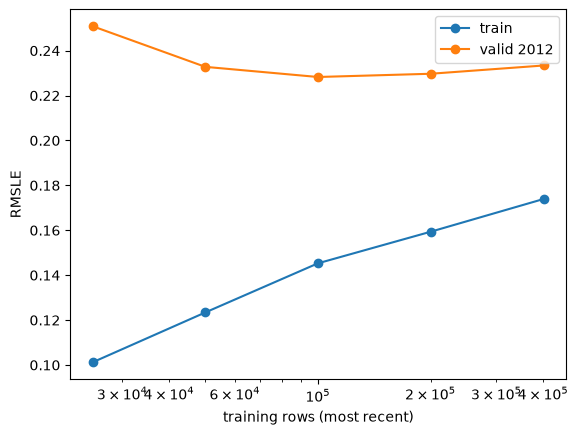

In [16]:
lc = {"n": [], "train": [], "valid": []}
for n in [25_000, 50_000, 100_000, 200_000, len(X_tr)]:
    m = lgb.LGBMRegressor(n_estimators=int(best_lgb * 1.1), **lgb_params).fit(X_tr.iloc[-n:], y_tr.iloc[-n:])
    lc["n"].append(n)
    lc["train"].append(root_mean_squared_log_error(np.expm1(y_tr.iloc[-n:]), np.expm1(m.predict(X_tr.iloc[-n:]))))
    lc["valid"].append(root_mean_squared_log_error(y_va, np.expm1(m.predict(X_va))))
    print(f"{n:>7,} rows | train {lc['train'][-1]:.4f} | valid {lc['valid'][-1]:.4f}")
RESULTS["learning_curve"] = lc
plt.plot(lc["n"], lc["train"], "o-", label="train"); plt.plot(lc["n"], lc["valid"], "o-", label="valid 2012")
plt.xscale("log"); plt.xlabel("training rows (most recent)"); plt.ylabel("RMSLE"); plt.legend(); plt.show()

### 7.4 What drives the predictions?

**Gain importance** measures how much each feature reduced the error across all splits. **SHAP values** (`pred_contrib=True`) split each prediction into per-feature contributions. Their mean absolute value is a more reliable importance measure.

In [17]:
gain = pd.Series(lgbm.booster_.feature_importance("gain"), index=X_tr.columns)
gain = (gain / gain.sum()).sort_values(ascending=False)
contrib = lgbm.predict(X_va, pred_contrib=True)[:, :-1]
shap_imp = pd.Series(np.abs(contrib).mean(axis=0), index=X_tr.columns).sort_values(ascending=False)
RESULTS["gain_top"] = gain.head(12).round(4).to_dict()
RESULTS["shap_top"] = shap_imp.head(12).round(4).to_dict()
pd.DataFrame({"gain share": gain.head(12), "mean |SHAP| (log price)": shap_imp.reindex(gain.head(12).index)})

,gain share,mean |SHAP| (log price)
fiProductClassDesc,0.371753,0.334660
fiModelDesc,0.160311,0.077179
machineAge,0.125726,0.147529
fiBaseModel,0.071323,0.056462
Enclosure,0.061001,0.075231
ProductGroup,0.046594,0.040365
YearMade,0.039948,0.065664
fiSecondaryDesc,0.033108,0.060059
saleYear,0.024973,0.030338
ModelID,0.012361,0.010641


### 7.5 Where does the model make its biggest errors?

Error broken down by product group and by price band on the 2012 validation sales.

In [18]:
best_pred = PREDS[BEST]
va = raw[raw.saledate.dt.year == 2012].copy()
va["pred"] = best_pred
va["log_err"] = np.log1p(va.pred) - np.log1p(va.SalePrice)
by_group = va.groupby("ProductGroupDesc").apply(lambda d: pd.Series({"RMSLE": np.sqrt((d.log_err**2).mean()), "n": len(d),
                                                                   "bias %": (np.expm1(d.log_err.mean())) * 100}))
bands = pd.cut(va.SalePrice, [0, 10_000, 20_000, 40_000, 80_000, 200_000], labels=["<10k", "10–20k", "20–40k", "40–80k", "80k+"])
by_band = va.groupby(bands, observed=True).apply(lambda d: pd.Series({"RMSLE": np.sqrt((d.log_err**2).mean()), "n": len(d),
                                                                       "bias %": (np.expm1(d.log_err.mean())) * 100}))
RESULTS["by_group"] = by_group.round(4).to_dict(orient="index")
RESULTS["by_band"] = by_band.round(4).to_dict(orient="index")
rng = np.random.default_rng(0); idx = rng.choice(len(va), 400, replace=False)
RESULTS["scatter"] = {"actual": va.SalePrice.values[idx].round(0).tolist(), "pred": va.pred.values[idx].round(0).tolist()}
within = np.abs(va.pred / va.SalePrice - 1)
RESULTS["within_10"] = float((within <= 0.10).mean()); RESULTS["within_25"] = float((within <= 0.25).mean())
print(f"Within ±10%: {RESULTS['within_10']:.1%} | within ±25%: {RESULTS['within_25']:.1%}")
display(by_group.sort_values("RMSLE"), by_band)

Within ±10%: 37.0% | within ±25%: 77.8%


,RMSLE,n,bias %
ProductGroupDesc,,,
Backhoe Loaders,0.185386,1986.0,-5.718944
Skid Steer Loaders,0.218127,1523.0,-3.670774
Motor Graders,0.228401,769.0,-6.634904
Wheel Loader,0.239783,2170.0,-2.902375
Track Excavators,0.244292,3063.0,-4.899531
Track Type Tractors,0.249824,2062.0,-3.978374


,RMSLE,n,bias %
SalePrice,,,
<10k,0.274789,1127.0,19.034236
10–20k,0.219163,3300.0,-1.267349
20–40k,0.216232,3582.0,-5.721293
40–80k,0.231037,2639.0,-10.330482
80k+,0.265365,925.0,-18.011514


## 8. Test-set predictions

Predictions for the 12,457 Kaggle test sales from the best model, using the **training categories** for encoding. The column is named `SalePrice`, as Kaggle expects.

In [19]:
if BEST == "CatBoost":
    test_pred = np.expm1(cbm.predict(cb_frame(X_te)))
elif BEST == "LightGBM":
    test_pred = np.expm1(lgbm.predict(X_te))
else:
    test_pred = np.expm1({"Random Forest": rf, "HistGradientBoosting": hgb, "XGBoost": xgbm}[BEST].predict(Xc_te))
sub = pd.DataFrame({"SalesID": test_raw.SalesID, "SalePrice": test_pred})
sub.to_csv("../data/processed/test_predictions_best_model.csv", index=False)
RESULTS["test"] = {"n": len(sub), "median": float(np.median(test_pred)), "min": float(test_pred.min()), "max": float(test_pred.max())}
sub.describe()

,SalesID,SalePrice
count,1.245700e+04,12457.000000
mean,5.787463e+06,31089.990788
std,1.470164e+06,22657.335567
min,1.227829e+06,5175.110326
25%,6.260703e+06,13463.308540
50%,6.300886e+06,23627.919670
75%,6.454946e+06,42159.281209
max,6.643196e+06,146807.492083


In [20]:
json.dump(RESULTS, open("../data/processed/model_comparison_results.json", "w"), indent=1, default=float)
print("saved model_comparison_results.json")

saved model_comparison_results.json


## 9. Findings

**1. CatBoost is the best single model.** Validation RMSLE on 2012 sales is **0.231**, compared with **0.245** for the original notebook's Random Forest (6% lower). A simple average of CatBoost, LightGBM, XGBoost does better still: **0.228** (7% lower).

**2. Like for like, every boosting model beats the Random Forest.** With identical features and splits, the Random Forest scores 0.250, HistGradientBoosting 0.246, XGBoost 0.238, LightGBM 0.233 and CatBoost 0.231. Boosting also wins on MAE, R² and MAPE in this like-for-like comparison.

**3. The gain comes from the model, not from the data preparation.** The new features and log target did not help the Random Forest (0.245 → 0.250), and the log target made no real difference for LightGBM (0.2329 on raw prices vs 0.2334). Note that the original Random Forest's settings were chosen using its 2012 score, while these models never saw 2012 before the final test.

**4. Dollar metrics barely move.** Compared with the original Random Forest, CatBoost's MAE is $5,977 vs $5,951, and its R² is 0.873 vs 0.882. RMSLE rewards relative accuracy, so the boosting models price cheap machines better but slightly under-price expensive ones ($80k+ sales are under-predicted by about 18% on average, while sales under $10k are over-predicted by about 19%).

**5. Accuracy in plain terms:** 37% of 2012 sales are predicted within ±10% of the true price, and 78% within ±25%.

**6. Stable over time.** Time-based cross-validation (LightGBM) gives RMSLE between 0.233 and 0.304 for 2008–2012. 2009, the recession year, is the hardest (0.304).

**7. Mild overfitting, and recent data matters most.** At full size the training RMSLE is 0.174 vs 0.233 on validation, a smaller gap than the original Random Forest's (0.145 vs 0.245). Validation error is lowest (0.228) when training on only the most recent 100,000 sales, so older sales add little.

**8. What drives price:** `fiProductClassDesc` (machine type and size), the new `machineAge` feature and the exact model (`fiModelDesc`) have the largest SHAP values.

**9. Speed trade-off:** CatBoost took about 17 minutes to train; LightGBM took 33 seconds for almost the same accuracy.

**Recommendation:** use CatBoost, or the top-3 blend, when RMSLE is what matters; use LightGBM when the model must be retrained often. Next, give recent sales more weight, tune with time-based cross-validation, and reduce the under-pricing of expensive machines.

Test predictions from CatBoost are saved in `test_predictions_best_model.csv` (`SalesID`, `SalePrice`). The slide deck `bulldozer_model_comparison.pptx` presents these findings.